# Day 4 · 그래프로 말하기 (데이터 분석)
AICE 2주 합격 플랜 · 영상 4편과 함께 풉니다. 60분, 손으로 직접 치세요.
- 그래프를 그린 뒤 **그래프를 보고 답을 저장**하는 문제가 시험에 자주 나옵니다.
- 이 노트북은 **해설**입니다.

_최종 수정 2026-10-20 · 바뀐 내용은 [안내 페이지의 업데이트 기록](https://pm-ainote.github.io/aice/#updates) · 개인 학습용, 재배포·판매 금지_

### 준비: 연습 데이터 내려받기
아래 셀을 먼저 실행하세요. 같은 폴더에 `aice_practice.csv` 가 생깁니다.

In [1]:
!wget -q -O aice_practice.csv https://raw.githubusercontent.com/pm-ainote/aice/main/data/aice_practice.csv
import os
print('준비 완료' if os.path.exists('aice_practice.csv') and os.path.getsize('aice_practice.csv') > 0 else '내려받기 실패: 이 셀을 다시 실행하세요')

준비 완료


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('aice_practice.csv')
df.shape

(600, 6)

## 1. [직접 작성] 성별(Sex)에 따른 생존(Survived) 개수를 countplot 으로 그리세요 (hue 사용)

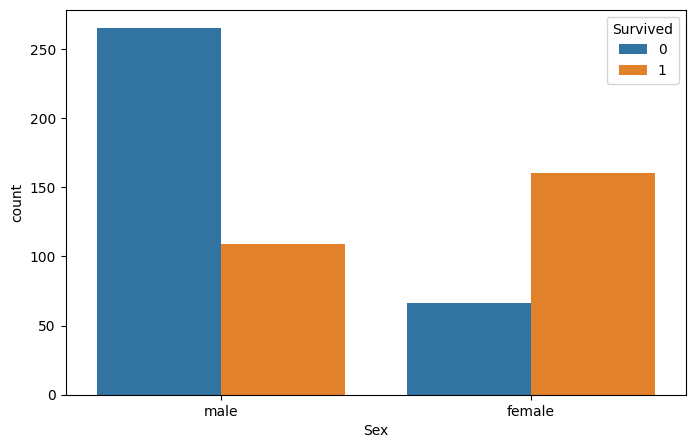

In [3]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Sex', hue='Survived')
plt.show()

## 2. [그래프 보고 답 저장] 1번 그래프에서 생존자(Survived=1)가 사망자보다 많은 성별을 `답안2` 에 저장하세요 ('male' 또는 'female')
- 색은 범례로 확인하세요. 노트북 기본 색은 파랑이 0(사망), 주황이 1(생존)로 영상과 다릅니다.

In [4]:
답안2 = 'female'
pd.crosstab(df['Sex'], df['Survived'])

Survived,0,1
Sex,,
female,66,160
male,265,109


## 3. [빈칸 채우기] Age 분포를 막대 20개와 분포 곡선으로 그리세요

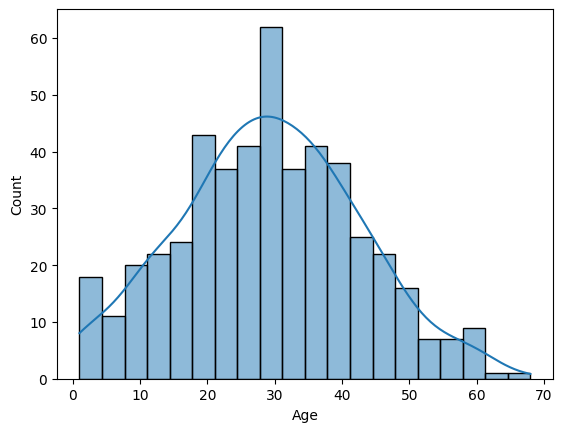

In [5]:
# 아래 코드의 빈칸을 채우고 실행하세요.
sns.histplot(data=df, x='Age', bins=20, kde=True)
plt.show()

## 4. [직접 작성] 등급(Pclass)별 요금(Fare)을 boxplot 으로 그리세요

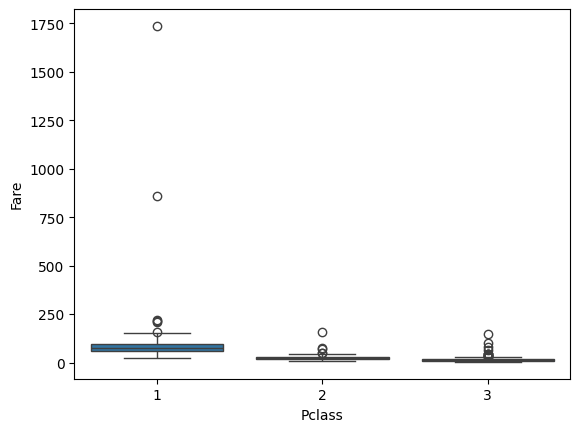

In [6]:
sns.boxplot(data=df, x='Pclass', y='Fare')
plt.show()

## 5. [그래프 보고 답 저장] 4번 그래프에서 이상치 점이 가장 많은 등급을 `답안5` 에 저장하세요 (1, 2, 3 중)
눈으로 세기 어렵다면 등급마다 IQR 울타리 밖 개수를 계산해 확인하세요.

In [7]:
답안5 = 3
# 확인
for c, g in df.groupby('Pclass'):
    q1, q3 = g['Fare'].quantile([0.25, 0.75]); iqr = q3 - q1
    print(c, ((g['Fare'] < q1 - 1.5 * iqr) | (g['Fare'] > q3 + 1.5 * iqr)).sum())

1 6
2 5
3 14


## 6. [오류 정정] jointplot 크기를 4x4 로 바꾸고 싶은데 아래 코드는 크기가 그대로입니다
- 에러는 안 납니다. jointplot 안에서 크기를 정하도록 고치세요.

In [ ]:
# 아래의 코드를 정정하고 실행하세요.
sns.jointplot(data=df, x='Age', y='Fare', height=4)   # jointplot 은 자기 도화지를 새로 만든다
plt.show()

## 7. [직접 작성] 숫자 컬럼의 상관계수를 heatmap 으로 그리고 칸에 숫자를 표시하세요

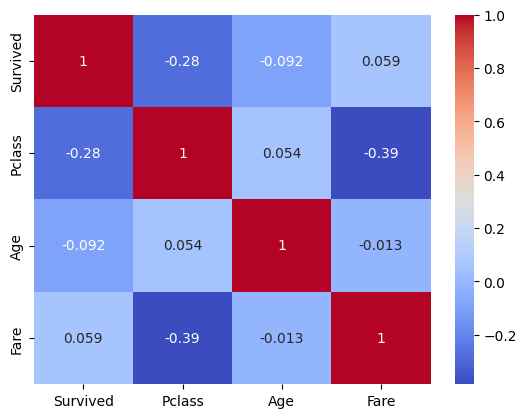

In [8]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

## 8. [그래프 보고 답 저장] 7번 그래프에서 Survived 와 상관계수의 절댓값이 가장 큰 컬럼 이름을 `답안8` 에 저장하세요

In [ ]:
답안8 = 'Pclass'
# 확인: df.corr(numeric_only=True)['Survived'].drop('Survived').abs().idxmax()

## 9. [오류 정정] 왼쪽 칸이 비고 두 그래프가 오른쪽 칸에 겹칩니다 (공식 샘플 subplots 형식)

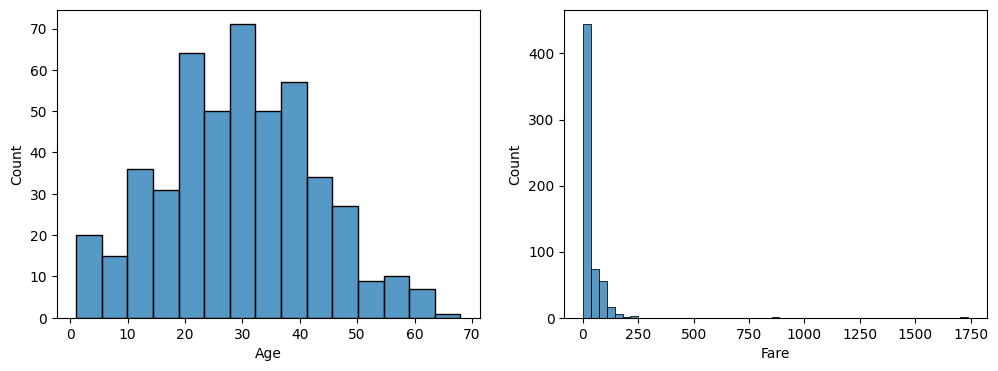

In [9]:
# 아래의 코드를 정정하고 실행하세요.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='Age', ax=axes[0])
sns.histplot(data=df, x='Fare', ax=axes[1])
plt.show()

## 10. [빈칸 채우기] 2행 2열 도화지의 오른쪽 위 칸에 Embarked 개수를 그리세요

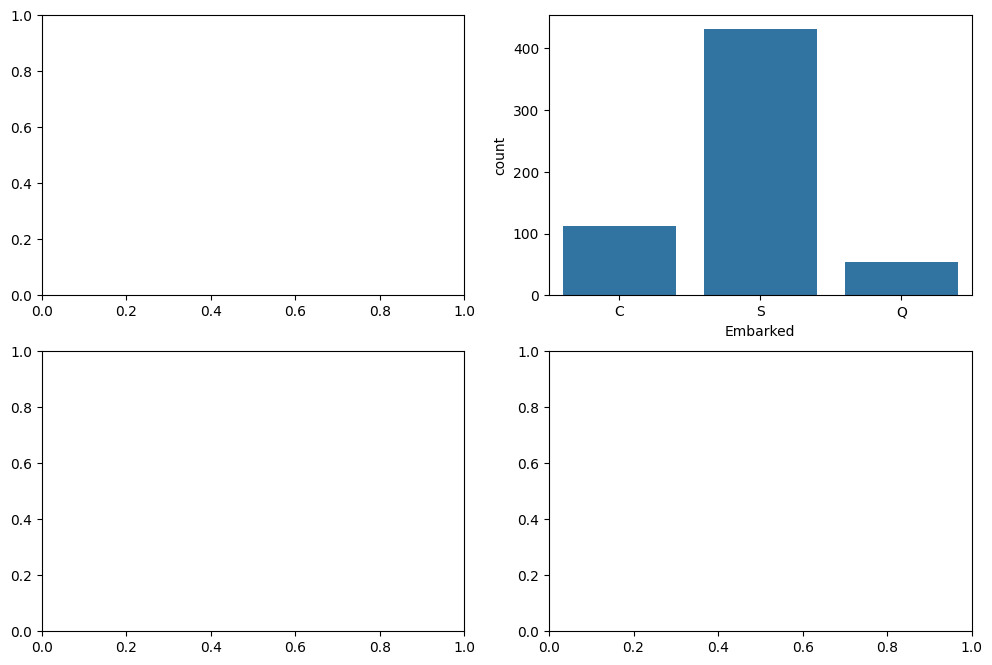

In [10]:
# 아래 코드의 빈칸을 채우고 실행하세요.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.countplot(data=df, x='Embarked', ax=axes[0, 1])   # 2x2 는 [행, 열]
plt.show()

## 11. [그래프 보고 답 저장] 등급별 생존율 막대그래프를 그리고, 생존율이 가장 높은 등급을 `답안11` 에 숫자로 저장하세요 (1, 2, 3 중)

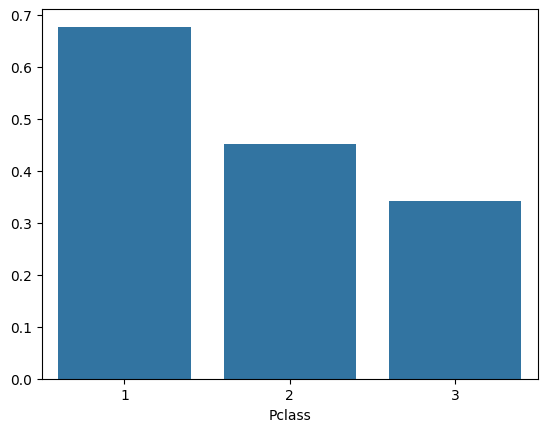

np.int64(1)

In [11]:
rate = df.groupby('Pclass')['Survived'].mean()
sns.barplot(x=rate.index, y=rate.values)
plt.show()
답안11 = rate.idxmax()
답안11

## 12. [빈칸 채우기] 샘플 3번 형식: 두 그래프를 가로로 나란히 그리고 제목을 붙이세요
- 왼쪽: Embarked 개수 countplot, 제목 'Port Count'
- 오른쪽: Survived 별 Age 분포 histplot (hue 사용), 제목 'Age by Survived'
- 빈칸 `< blank12-1 >`, `< blank12-2 >`, `< blank12-3 >` 에 들어갈 말을 `답안12_1`, `답안12_2`, `답안12_3` 에 문자열로 저장하세요.

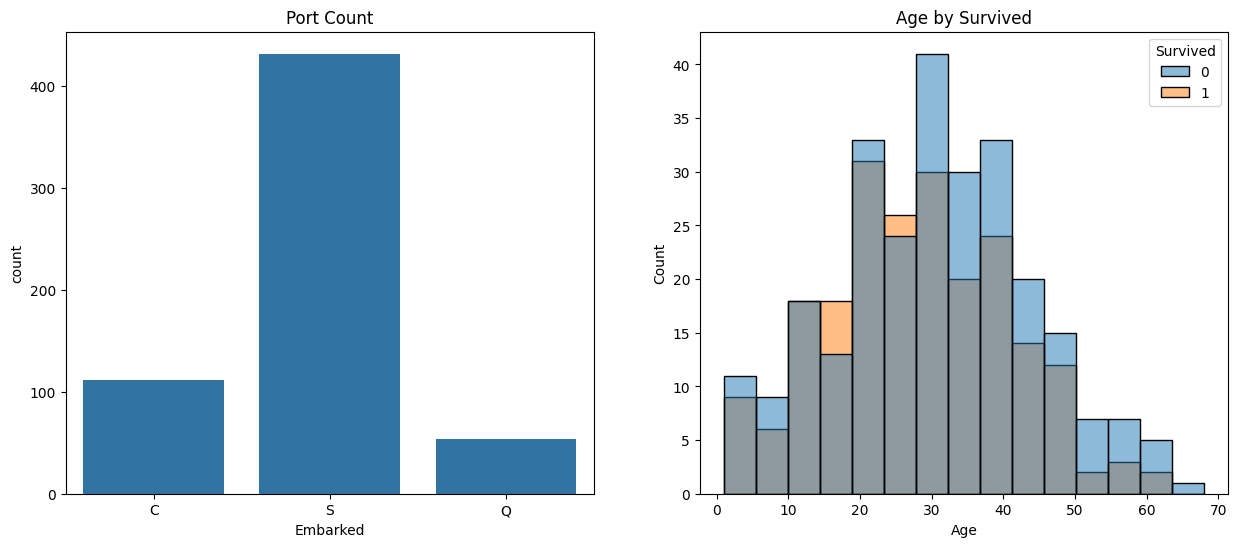

In [13]:
# 아래 코드의 빈칸을 채우고 실행하세요.
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 6))
sns.countplot(data=df, x='Embarked', ax=axes[0])
sns.histplot(data=df, x='Age', hue='Survived', ax=axes[1])
axes[0].set_title('Port Count')
axes[1].set_title('Age by Survived')
plt.show()
답안12_1 = 'subplots'
답안12_2 = 'axes'
답안12_3 = 'set_title'

---
### 오늘의 체크
- [ ] 개수 countplot · 분포 histplot · 그룹과 이상치 boxplot · 관계 jointplot · 상관 heatmap
- [ ] hue 는 색으로 한 번 더 나누기, kde 는 곡선, annot 은 칸에 숫자
- [ ] jointplot 크기는 height=
- [ ] subplots(nrows=, ncols=) 는 ax=axes[i], 제목은 axes[i].set_title, 2x2 는 axes[행, 열]
- [ ] 그래프로 방향, 숫자로 확정